# SIS 1. Weather & Tourism Trends

**Question:** Do cities with a warmer and drier climate have more tourist attractions listed on Wikipedia?

**Data sources**
1. API – Open-Meteo Historical Weather API: https://archive-api.open-meteo.com/v1/archive (daily temperature and precipitation for 2025)
2. Web scraping – Wikipedia category pages: https://en.wikipedia.org/wiki/Category:Tourist_attractions_in_<City>

**Tools:** Python, Requests, BeautifulSoup, Pandas, Matplotlib, Seaborn

In [1]:
!pip install -q requests beautifulsoup4 pandas matplotlib seaborn

In [2]:
import time
from urllib.robotparser import RobotFileParser

import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup

## 1. Cities

10 popular tourist cities with their coordinates (needed for the weather API) and their name in Wikipedia URLs.

In [3]:
cities = pd.DataFrame([
    ["Paris", "France", 48.86, 2.35, "Paris"],
    ["London", "United Kingdom", 51.51, -0.13, "London"],
    ["Rome", "Italy", 41.90, 12.50, "Rome"],
    ["Barcelona", "Spain", 41.39, 2.17, "Barcelona"],
    ["Istanbul", "Turkey", 41.01, 28.98, "Istanbul"],
    ["Dubai", "UAE", 25.20, 55.27, "Dubai"],
    ["Bangkok", "Thailand", 13.76, 100.50, "Bangkok"],
    ["Tokyo", "Japan", 35.68, 139.65, "Tokyo"],
    ["New York", "USA", 40.71, -74.01, "New_York_City"],
    ["Almaty", "Kazakhstan", 43.24, 76.89, "Almaty"],
], columns=["city", "country", "lat", "lon", "wiki_name"])
cities

,city,country,lat,lon,wiki_name
0,Paris,France,48.86,2.35,Paris
1,London,United Kingdom,51.51,-0.13,London
2,Rome,Italy,41.90,12.50,Rome
3,Barcelona,Spain,41.39,2.17,Barcelona
4,Istanbul,Turkey,41.01,28.98,Istanbul
5,Dubai,UAE,25.20,55.27,Dubai
6,Bangkok,Thailand,13.76,100.50,Bangkok
7,Tokyo,Japan,35.68,139.65,Tokyo
8,New York,USA,40.71,-74.01,New_York_City
9,Almaty,Kazakhstan,43.24,76.89,Almaty


## 2. Data collection from the API (Open-Meteo)

For each city one request returns daily mean temperature and daily precipitation for the whole year 2025 in JSON format.

In [4]:
API_URL = "https://archive-api.open-meteo.com/v1/archive"

weather_parts = []
for _, row in cities.iterrows():
    params = {
        "latitude": row["lat"],
        "longitude": row["lon"],
        "start_date": "2025-01-01",
        "end_date": "2025-12-31",
        "daily": "temperature_2m_mean,precipitation_sum",
        "timezone": "auto",
    }
    response = requests.get(API_URL, params=params, timeout=30)
    data = response.json()
    part = pd.DataFrame(data["daily"])
    part["city"] = row["city"]
    weather_parts.append(part)
    print(row["city"], response.status_code, len(part), "days")
    time.sleep(1)

weather_raw = pd.concat(weather_parts, ignore_index=True)
weather_raw.head()

Paris 200 365 days
London 200 365 days
Rome 200 365 days
Barcelona 200 365 days
Istanbul 200 365 days
Dubai 200 365 days
Bangkok 200 365 days
Tokyo 200 365 days
New York 200 365 days
Almaty 200 365 days


,time,temperature_2m_mean,precipitation_sum,city
0,2025-01-01,6.5,0.1,Paris
1,2025-01-02,4.1,22.6,Paris
2,2025-01-03,0.3,0.0,Paris
3,2025-01-04,-0.5,6.0,Paris
4,2025-01-05,9.8,13.0,Paris


In [5]:
weather_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   time                 3650 non-null   object 
 1   temperature_2m_mean  3650 non-null   float64
 2   precipitation_sum    3650 non-null   float64
 3   city                 3650 non-null   object 
dtypes: float64(2), object(2)
memory usage: 114.2+ KB


## 3. Data collection by web scraping (Wikipedia)

First robots.txt is checked to make sure scraping category pages is allowed. Then for each city the category page is downloaded and every link in the lists of pages and subcategories is saved as one attraction.

In [6]:
HEADERS = {"User-Agent": "SIS1-student-project/1.0 (educational use)"}

robots = RobotFileParser()
robots.parse(requests.get("https://en.wikipedia.org/robots.txt", headers=HEADERS, timeout=30).text.splitlines())
print("Allowed:", robots.can_fetch(HEADERS["User-Agent"], "https://en.wikipedia.org/wiki/Category:Tourist_attractions_in_Paris"))

Allowed: True


In [7]:
attraction_rows = []
for _, row in cities.iterrows():
    url = "https://en.wikipedia.org/wiki/Category:Tourist_attractions_in_" + row["wiki_name"]
    response = requests.get(url, headers=HEADERS, timeout=30)
    print(row["city"], response.status_code)
    if response.status_code != 200:
        continue
    soup = BeautifulSoup(response.text, "html.parser")
    for block_id in ["mw-subcategories", "mw-pages"]:
        block = soup.find("div", id=block_id)
        if block is None:
            continue
        for link in block.find_all("li"):
            attraction_rows.append({"city": row["city"], "name": link.get_text(), "type": block_id})
    time.sleep(1)

attractions_raw = pd.DataFrame(attraction_rows)
print(attractions_raw.shape)
attractions_raw.head(10)

Paris 200
London 200
Rome 200
Barcelona 200
Istanbul 200
Dubai 200
Bangkok 200
Tokyo 200
New York 200
Almaty 200
(595, 3)


,city,name,type
0,Paris,Amusement parks in Paris (8 P),mw-subcategories
1,Paris,Aquaria in Paris (2 P),mw-subcategories
2,Paris,"Cemeteries in Paris (1 C, 26 P)",mw-subcategories
3,Paris,"Champs-Élysées (1 C, 14 P)",mw-subcategories
4,Paris,"Châteaux in Paris (1 C, 13 P)",mw-subcategories
5,Paris,"Churches in Paris (6 C, 4 P)",mw-subcategories
6,Paris,Coffeehouses and cafés in Paris (20 P),mw-subcategories
7,Paris,"Entertainment venues in Paris (9 C, 16 P)",mw-subcategories
8,Paris,Fountains in Paris (25 P),mw-subcategories
9,Paris,Gardens in Paris (23 P),mw-subcategories


## 4. Data cleaning

### 4.1 Weather data

In [8]:
weather = weather_raw.rename(columns={
    "time": "date",
    "temperature_2m_mean": "temp_c",
    "precipitation_sum": "rain_mm",
})
weather["date"] = pd.to_datetime(weather["date"])

print("Missing values before:")
print(weather.isna().sum())
print("Duplicates:", weather.duplicated(["city", "date"]).sum())

Missing values before:
date       0
temp_c     0
rain_mm    0
city       0
dtype: int64
Duplicates: 0


In [9]:
weather = weather.drop_duplicates(["city", "date"])
weather["temp_c"] = weather.groupby("city")["temp_c"].transform(lambda s: s.interpolate())
weather["rain_mm"] = weather["rain_mm"].fillna(0)

print("Missing values after:")
print(weather.isna().sum())
weather.dtypes

Missing values after:
date       0
temp_c     0
rain_mm    0
city       0
dtype: int64


,0
date,datetime64[ns]
temp_c,float64
rain_mm,float64
city,object


Missing temperatures (if any) are filled by interpolation between the neighbouring days, missing precipitation is treated as 0 mm.

### 4.2 Attractions data

In [10]:
attractions = attractions_raw.copy()
attractions["name"] = attractions["name"].str.replace("\u200e", "", regex=False)
attractions["name"] = attractions["name"].str.replace(r"\s*\((\d+ [CPF],? ?)+\)$", "", regex=True)
attractions["name"] = attractions["name"].str.replace(r"\s+", " ", regex=True).str.strip()
attractions["type"] = attractions["type"].replace({"mw-pages": "page", "mw-subcategories": "subcategory"})

print("Empty names:", (attractions["name"] == "").sum())
print("Duplicates:", attractions.duplicated(["city", "name"]).sum())
attractions = attractions[attractions["name"] != ""].drop_duplicates(["city", "name"])
print(attractions.shape)

Empty names: 0
Duplicates: 9
(586, 3)


## 5. Merging

The daily weather is summarised to one row per city, the attractions are counted per city, and both tables are merged with the city list by the `city` column. A city without a Wikipedia category page gets 0 attractions.

In [11]:
weather_summary = weather.groupby("city").agg(
    avg_temp_c=("temp_c", "mean"),
    total_rain_mm=("rain_mm", "sum"),
    rainy_days=("rain_mm", lambda s: (s >= 1).sum()),
).round(1).reset_index()

attraction_counts = attractions.groupby("city").size().reset_index(name="attractions")

df = cities[["city", "country"]].merge(weather_summary, on="city", how="left")
df = df.merge(attraction_counts, on="city", how="left")
df["attractions"] = df["attractions"].fillna(0).astype(int)
df = df.sort_values("attractions", ascending=False).reset_index(drop=True)
df

,city,country,avg_temp_c,total_rain_mm,rainy_days,attractions
0,Paris,France,12.8,740.9,120,100
1,London,United Kingdom,12.4,613.4,107,79
2,Rome,Italy,17.3,1024.3,105,73
3,Barcelona,Spain,17.0,912.7,108,73
4,Tokyo,Japan,16.9,1322.1,126,63
5,Bangkok,Thailand,28.2,1675.3,207,58
6,Istanbul,Turkey,15.8,631.7,92,53
7,Dubai,UAE,28.5,37.1,7,42
8,New York,USA,12.5,1116.1,119,30
9,Almaty,Kazakhstan,11.5,345.8,53,15


## 6. Analysis

In [12]:
df.describe().round(1)

,avg_temp_c,total_rain_mm,rainy_days,attractions
count,10.0,10.0,10.0,10.0
mean,17.3,841.9,104.4,58.6
std,6.2,476.0,51.4,24.9
min,11.5,37.1,7.0,15.0
25%,12.6,618.0,95.2,44.8
50%,16.4,826.8,107.5,60.5
75%,17.2,1093.1,119.8,73.0
max,28.5,1675.3,207.0,100.0


In [13]:
correlation = df[["avg_temp_c", "total_rain_mm", "rainy_days", "attractions"]].corr().round(2)
correlation

,avg_temp_c,total_rain_mm,rainy_days,attractions
avg_temp_c,1.00,0.12,0.06,-0.06
total_rain_mm,0.12,1.00,0.93,0.23
rainy_days,0.06,0.93,1.00,0.37
attractions,-0.06,0.23,0.37,1.00


In [14]:
print("Most attractions:", df.loc[df["attractions"].idxmax(), "city"])
print("Warmest city:", df.loc[df["avg_temp_c"].idxmax(), "city"])
print("Wettest city:", df.loc[df["total_rain_mm"].idxmax(), "city"])
print("Correlation temperature vs attractions:", correlation.loc["avg_temp_c", "attractions"])
print("Correlation rain vs attractions:", correlation.loc["total_rain_mm", "attractions"])

Most attractions: Paris
Warmest city: Dubai
Wettest city: Bangkok
Correlation temperature vs attractions: -0.06
Correlation rain vs attractions: 0.23


## 7. Visualizations

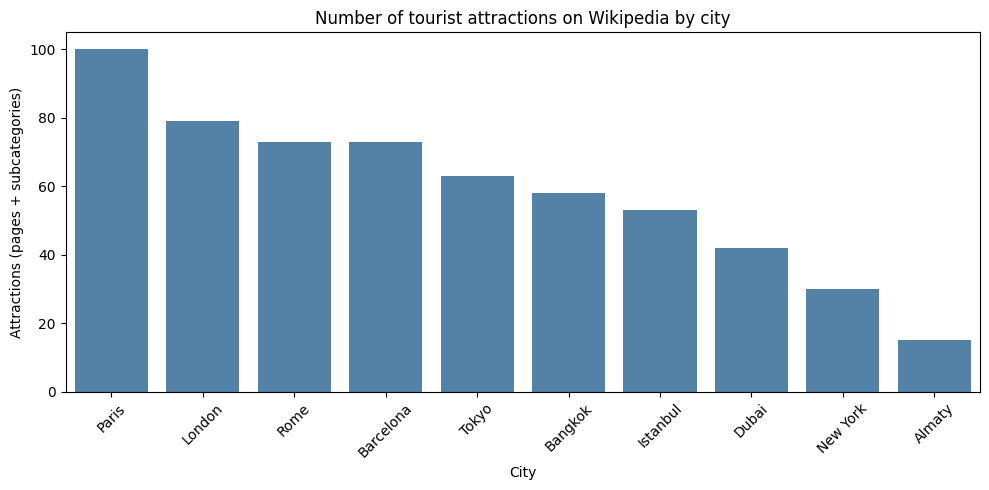

In [15]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="city", y="attractions", color="steelblue")
plt.title("Number of tourist attractions on Wikipedia by city")
plt.xlabel("City")
plt.ylabel("Attractions (pages + subcategories)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

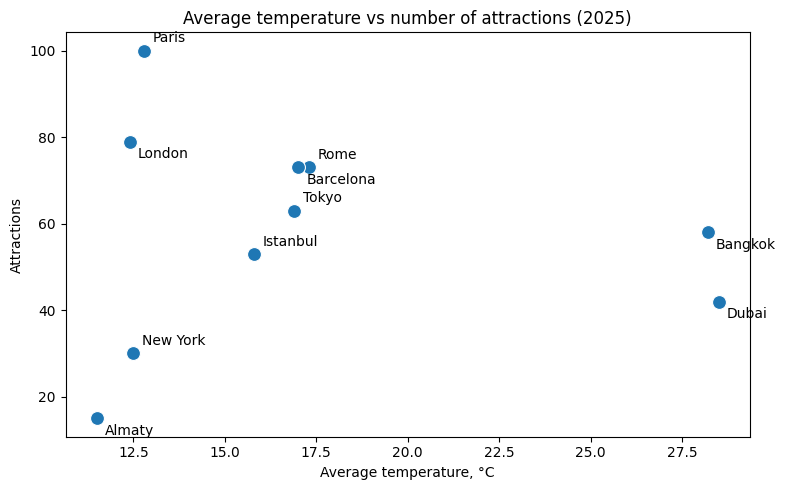

In [16]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="avg_temp_c", y="attractions", s=100)
for i, row in df.iterrows():
    plt.annotate(row["city"], (row["avg_temp_c"], row["attractions"]), xytext=(6, 6 if i % 2 == 0 else -12), textcoords="offset points")
plt.title("Average temperature vs number of attractions (2025)")
plt.xlabel("Average temperature, °C")
plt.ylabel("Attractions")
plt.tight_layout()
plt.show()

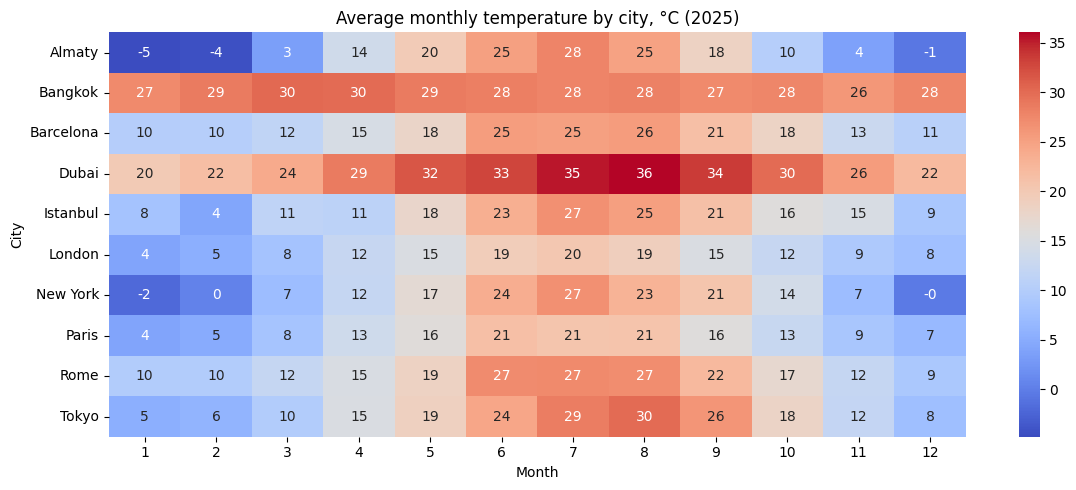

In [17]:
monthly = weather.groupby(["city", weather["date"].dt.month])["temp_c"].mean().unstack()
plt.figure(figsize=(12, 5))
sns.heatmap(monthly, annot=True, fmt=".0f", cmap="coolwarm")
plt.title("Average monthly temperature by city, °C (2025)")
plt.xlabel("Month")
plt.ylabel("City")
plt.tight_layout()
plt.show()

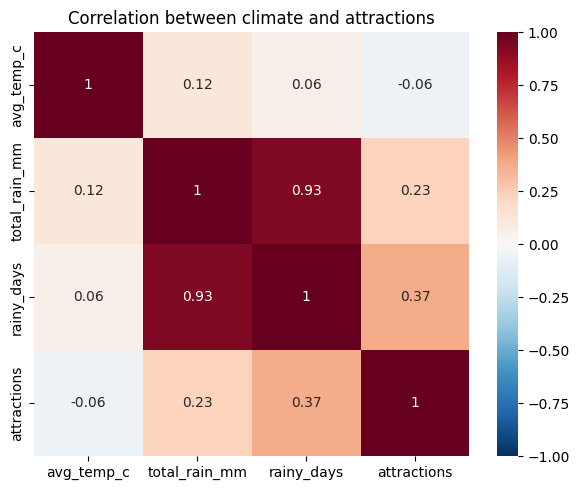

In [18]:
plt.figure(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation between climate and attractions")
plt.tight_layout()
plt.show()

## 8. Conclusions

1. **Paris has the most attractions (100), Almaty the fewest (15).** The top four are European cities: Paris, London (79), Rome and Barcelona (73 each).
2. **Temperature is not related to the number of attractions.** The correlation is -0.06: the two warmest cities, Dubai (28.5 °C) and Bangkok (28.2 °C), are in the middle of the ranking, while cool Paris and London are at the top.
3. **Rain shows only a weak positive relation.** The correlation is 0.23 for total precipitation and 0.37 for rainy days. Dubai is the driest city (37.1 mm, 7 rainy days) but has only 42 attractions, and Bangkok is the wettest (1675.3 mm, 207 rainy days) with 58.
4. **Climate does not explain tourism activity in this sample.** The number of attractions depends more on the history and size of a city and on how well it is covered on English Wikipedia; for example, New York has only 30 even though it is one of the most visited cities in the world.
5. **Limitations:** only 10 cities and one year (2025); a subcategory is counted as one attraction; Wikipedia coverage is not the same as real tourist numbers.